# Bures-Wasserstein distance between geometries (paper Fig. 6, appendix)

* **Goal**: plot Fig. 6, the Bures-Wasserstein distance `d_BW` between the reconstructed geometries of two models or two areas, as a function of the number `k` of leading eigenvectors kept. It is the check that the conclusions of Fig. 4D-E, based on the subspace alignment, do not depend on the similarity measure: the alignment compares only the orientation of the leading eigenvectors, while `d_BW` also penalises differences in scale.
* **Distance**: for two metrics `A` and `B` with rank-`k` reconstructions `V_A diag(l_A) V_A^T` and `V_B diag(l_B) V_B^T`, `d_BW(A, B)^2 = tr(A) + tr(B) - 2 tr((A^(1/2) B A^(1/2))^(1/2))`. Stage 5 computes it without forming the 4096 x 4096 matrices, for `k = 1..50` and for every pair of (encoder, area) configurations, and averages over the test images that the two configurations share.
* **Four comparisons**: V1 against V4 within Inception and within ResNet-50 (same model, different areas, dashed), and Inception against ResNet-50 within V1 and within V4 (same area, different models, solid). Left: the multi-scale metric G(x). Right: the Fisher metric J(x).
* **What the paper reports**: for G(x) the cross-model distances (solid) lie below the cross-area distances (dashed); for J(x) the order reverses. This is the same order as in Fig. 4D-E.
* All supporting functions are in `src/bures_wasserstein.py`; this notebook only sets parameters and calls them.

## 1. Inputs

The distances are computed from the per-image eigenvectors and eigenvalues of G(x) and J(x) in `runs/per_image/`, which notebook 2 (`2_subspace_alignment.ipynb`) estimates for the images and configurations you choose. The paper averages over 200 test images and all configurations; with fewer images the curves are noisier. At least two configurations are needed, and all four comparisons of the figure need inception and resnet50 for both V1 and V4.

In [1]:
%%time

# import built-in packages
import os, sys
from pathlib import Path
import importlib

# move to the repository root
root = Path.cwd().resolve()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))

# import custom packages
from src import bures_wasserstein as bw
from src import subspace_alignment as sa
importlib.reload(bw)      # update the modules without restarting the kernel

# parameters
RUNS_DIR = "runs"         # folder with per_image/<encoder>/<area>/img*.pt (written by notebook 2)

summary = bw.print_inputs(RUNS_DIR)

inception  V1:   6 images
inception  V4:   3 images
resnet50   V1:   2 images
resnet50   V4:   2 images
fewest images shared by two configurations: 2  (the paper averages over 200: with fewer, the bands are wider)
CPU times: user 935 μs, sys: 982 μs, total: 1.92 ms
Wall time: 1.86 ms


## 2. Stage 5: the distances

Runs `stages/05_compute_metrics.py` (minutes at most, on the CPU) and writes `runs/metrics/cross_encoder_metrics.json`, which also holds the subspace alignment of Fig. 4D-E. It does nothing if fewer than two configurations have per-image files.

In [2]:
%%time

metrics_path = sa.compute_metrics(RUNS_DIR, out_dir=f"{RUNS_DIR}/metrics")

[Stage 5] Found 4 (encoder, area) configs:
     inception / V1: 6 images
     inception / V4: 3 images
      resnet50 / V1: 2 images
      resnet50 / V4: 2 images
[Stage 5] Saved 12 pairwise comparisons to runs/metrics/cross_encoder_metrics.json

[Stage 5] Paper comparisons (mean over images):
  cross_area_inception__G                       A_20 = 0.505 ± 0.032   d_BW(k=20) = 1.32   n = 3
  cross_area_inception__J                       A_20 = 0.425 ± 0.047   d_BW(k=20) = 45   n = 3
  cross_area_resnet50__G                        A_20 = 0.476 ± 0.046   d_BW(k=20) = 1.34   n = 2
  cross_area_resnet50__J                        A_20 = 0.283 ± 0.056   d_BW(k=20) = 45.6   n = 2
  cross_model_V1_inception_resnet50__G          A_20 = 0.834 ± 0.030   d_BW(k=20) = 0.526   n = 2
  cross_model_V1_inception_resnet50__J          A_20 = 0.146 ± 0.022   d_BW(k=20) = 60.1   n = 2
  cross_model_V4_inception_resnet50__G          A_20 = 0.833 ± 0.010   d_BW(k=20) = 0.654   n = 2
  cross_model_V4_inception

## 3. Does the order match the paper?

The mean of `d_BW` over `k` for the two cross-model comparisons and the two cross-area comparisons, for each metric. The paper reports cross-model below cross-area for G(x) and the reverse for J(x).

In [3]:
if metrics_path is None:
    print("Nothing to check yet: stage 5 needs at least two configurations (see the message above).")
else:
    metrics = bw.load_metrics(metrics_path)
    order = bw.print_ordering(metrics)

G: mean d_BW over k: cross-model 0.597, cross-area 1.29  -> paper expects cross-model below cross-area: yes
J: mean d_BW over k: cross-model 54.4, cross-area 44.6  -> paper expects cross-model above cross-area: yes


## 4. Plot Fig. 6

Solid: different models, same area. Dashed: the same model, V1 versus V4. Bands: s.e.m. across the images. The paper also compares ON-OFF, for which there are no checkpoints here.

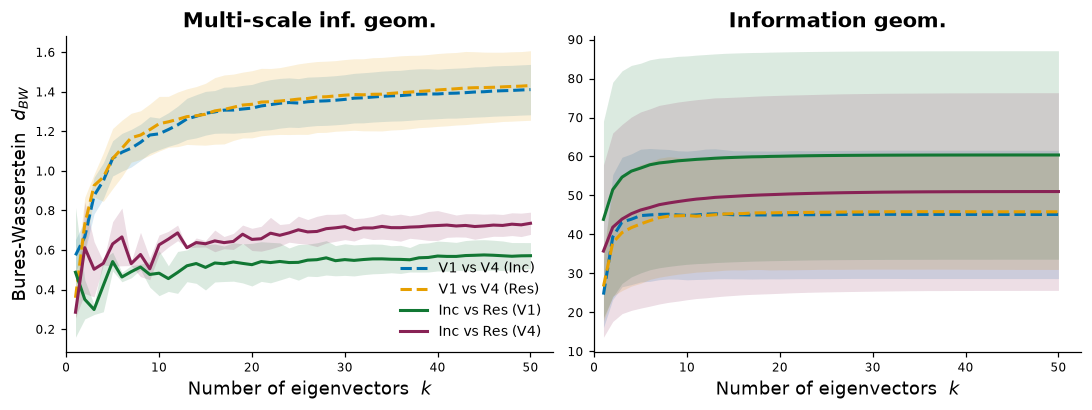

CPU times: user 3.27 s, sys: 103 ms, total: 3.38 s
Wall time: 1.04 s


In [4]:
%%time

if metrics_path is None:
    print("Nothing to plot yet: run the cells above first.")
else:
    sa.show_figure(bw.plot_bures_wasserstein(metrics))